<a href="https://colab.research.google.com/github/Swathims1/BIS-LAB/blob/main/PSO_Week03.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Iteration 1: Best Fitness = 0.27305855
Iteration 2: Best Fitness = 0.19181709
Iteration 3: Best Fitness = 0.02755729
Iteration 4: Best Fitness = 0.02755729
Iteration 5: Best Fitness = 0.02755729
Iteration 6: Best Fitness = 0.02755729
Iteration 7: Best Fitness = 0.02755729
Iteration 8: Best Fitness = 0.01559397
Iteration 9: Best Fitness = 0.01559397
Iteration 10: Best Fitness = 0.00897491
Iteration 11: Best Fitness = 0.00897491
Iteration 12: Best Fitness = 0.00142452
Iteration 13: Best Fitness = 0.00142452
Iteration 14: Best Fitness = 0.00142452
Iteration 15: Best Fitness = 0.00142452
Iteration 16: Best Fitness = 0.00142452
Iteration 17: Best Fitness = 0.00142452
Iteration 18: Best Fitness = 0.00142452
Iteration 19: Best Fitness = 0.00142452
Iteration 20: Best Fitness = 0.00142452
Iteration 21: Best Fitness = 0.00082278
Iteration 22: Best Fitness = 0.00009715
Iteration 23: Best Fitness = 0.00009715
Iteration 24: Best Fitness = 0.00002355
Iteration 25: Best Fitness = 0.00002355
Iteration

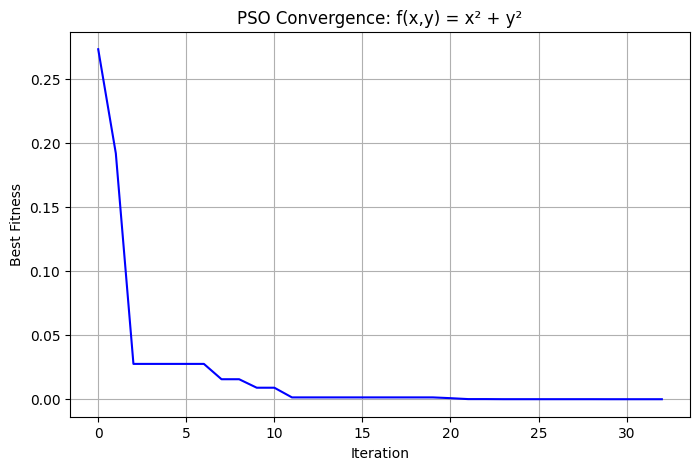

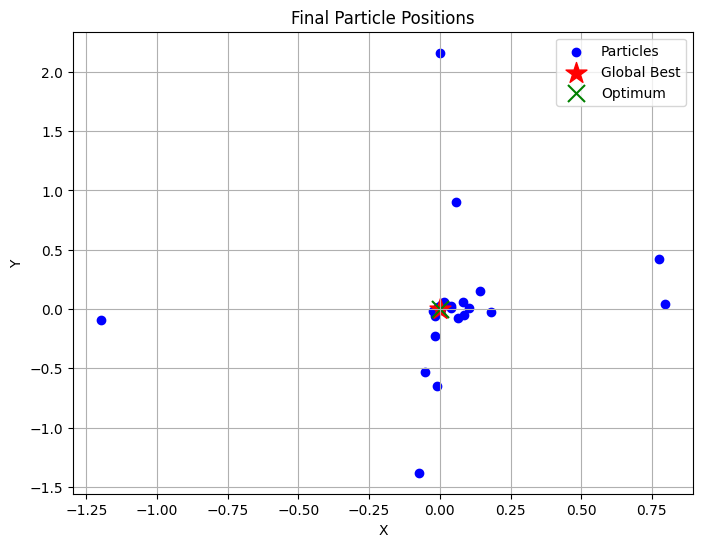

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Initialize parameters
num_particles = 30
num_dimensions = 2
max_iterations = 100
w, c1, c2 = 0.7, 1.5, 1.5
lower_bound, upper_bound = -10, 10
tolerance = 1e-6

# Fitness function
def fitness_function(position):
    x, y = position
    return x**2 + y**2

# Generate initial swarm
positions = np.random.uniform(lower_bound, upper_bound, (num_particles, num_dimensions))
velocities = np.random.uniform(-1, 1, (num_particles, num_dimensions))

# Evaluate initial fitness
fitness = np.array([fitness_function(p) for p in positions])

# Set personal best
personal_best_positions = positions.copy()
personal_best_fitness = fitness.copy()

# Set global best
index = np.argmin(personal_best_fitness)
global_best_position = personal_best_positions[index].copy()
global_best_fitness = personal_best_fitness[index]

best_fitness_history = []

# PSO optimization
for iteration in range(max_iterations):
    if global_best_fitness <= tolerance:
        break

    r1 = np.random.random((num_particles, num_dimensions))
    r2 = np.random.random((num_particles, num_dimensions))

    velocities = (w * velocities
                  + c1 * r1 * (personal_best_positions - positions)
                  + c2 * r2 * (global_best_position - positions))

    positions = np.clip(positions + velocities, lower_bound, upper_bound)

    fitness = np.array([fitness_function(p) for p in positions])

    for i in range(num_particles):
        if fitness[i] < personal_best_fitness[i]:
            personal_best_positions[i] = positions[i].copy()
            personal_best_fitness[i] = fitness[i]

    index = np.argmin(personal_best_fitness)

    if personal_best_fitness[index] < global_best_fitness:
        global_best_position = personal_best_positions[index].copy()
        global_best_fitness = personal_best_fitness[index]

    best_fitness_history.append(global_best_fitness)

    print(f"Iteration {iteration + 1}: Best Fitness = {global_best_fitness:.8f}")

# Final result
print("\n========== RESULT ==========")
print(f"Best x = {global_best_position[0]:.10f}")
print(f"Best y = {global_best_position[1]:.10f}")
print(f"Minimum fitness = {global_best_fitness:.10f}")

# Convergence graph
plt.figure(figsize=(8, 5))
plt.plot(best_fitness_history, color="blue")
plt.xlabel("Iteration")
plt.ylabel("Best Fitness")
plt.title("PSO Convergence: f(x,y) = x² + y²")
plt.grid()
plt.show()

# Final particle positions
plt.figure(figsize=(8, 6))
plt.scatter(positions[:, 0], positions[:, 1], color="blue", label="Particles")
plt.scatter(global_best_position[0], global_best_position[1], color="red", marker="*", s=250, label="Global Best")
plt.scatter(0, 0, color="green", marker="x", s=150, label="Optimum")
plt.xlabel("X")
plt.ylabel("Y")
plt.title("Final Particle Positions")
plt.legend()
plt.grid()
plt.show()
